# LangGraph 기반 Agentic RAG — Step 4. RAGAS 기반 답변 품질 평가

— 인공지능기본법 QA
> RAGAS(RAG + Assessment) : RAG 파이프라인의 답변 품질을 "정답 문장" 없이도 LLM-as-judge 방식으로 자동 채점해주는 평가 프레임워크

[1-3.agentic_rag.ipynb](./1-3.agentic_rag.ipynb)에서 완성한 Agentic RAG 그래프를 그대로 재사용하고,
그 출력(답변ㆍ검색된 조문)을 **RAGAS**로 정량 평가한다.

- `eval/evaluate.py`는 키워드 포함률ㆍ조문 일치 여부 같은 규칙 기반 지표라 LLM-as-judge 없이 결정적으로 동작한다.
- 이번 실습은 그와 별개로, 답변의 의미적 품질(근거 충실성ㆍ질문 적합성ㆍ검색 정확도)을 RAGAS의 LLM-as-judge 지표로 보완 평가한다.
- 사용 지표는 모두 **정답 문장(ground truth) 없이** 계산 가능한 것만 골랐다 — `golden_set.jsonl`에는 기대 조문ㆍ키워드만 있고 완전한 정답 문장이 없기 때문이다.
  - `Faithfulness`: 답변의 주장이 검색된 조문에 근거하는가(충실성)
  - `ResponseRelevancy`: 답변이 질문에 적합한가(답변 관련성)
  - `LLMContextPrecisionWithoutReference`: 검색된 조문이 질문과 관련 있는가(컨텍스트 정밀도)
- `route="general"`이거나 `no_evidence`로 끝나 `documents`가 빈 문항은 context 기반 지표를 계산할 수 없으므로 평가 대상에서 제외하고 별도로 집계한다.

> 트레이드오프: RAGAS는 내부적으로 LLM을 호출(judge)해 평가하므로 `eval/evaluate.py`보다 비용ㆍ지연이 늘고 결과가 완전히 결정적이지 않다.
>
> 사전 조건: 1-3과 동일(Qdrant 실행 + 색인) + `uv add ragas` 설치 완료


## 0. 환경 설정

In [1]:
from typing import Literal, TypedDict

from IPython.display import Image, Markdown, display
from langchain_core.caches import InMemoryCache
from langchain_core.globals import set_llm_cache
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

from common.ai_model import get_llm_model
from common.config import QDRANT_COLLECTION, RERANK_TOP_N, RETRIEVAL_TOP_K
from common.qdrant import get_qdrant_client
from rag.chunker import format_article_label
from rag.reranker import rerank
from rag.retriever import RetrievedChunk, retrieve

In [2]:
# Qdrant 컬렉션과 색인된 Chunk 수 확인
client = get_qdrant_client()
count = client.count(collection_name=QDRANT_COLLECTION).count
print(f"컬렉션: {QDRANT_COLLECTION} / Chunk 수: {count}")

컬렉션: ai_basic_law / Chunk 수: 3


In [3]:
# 동일 질문 반복 호출 시 토큰 비용을 아끼기 위한 인메모리 LLM 캐시
# (프로세스 내 캐시이므로 노트북 재시작 시 초기화됨)
set_llm_cache(InMemoryCache())

# 판단(라우팅ㆍ평가ㆍ검증)용 LLM과 답변 생성용 LLM
judge_llm = get_llm_model(max_tokens=256, model="gpt-5.4-mini")
answer_llm = get_llm_model(max_tokens=1024, model="gpt-5.4-mini")

### 공통 헬퍼

- `search_law`: `rag` 모듈의 **Hybrid 검색(Dense+BM25, RRF) → LLM Rerank**를 한 번에 호출
- `format_context` / `format_sources`: 검색 결과를 LLM 입력용 / 출력용 문자열로 변환
- `show_graph`: 그래프 구조 시각화 (PNG 렌더링 실패 시 Mermaid 텍스트 출력)

In [4]:
def search_law(query: str) -> list[RetrievedChunk]:
    """rag 모듈로 Hybrid 검색 후 Rerank해 상위 N개 조문을 반환한다."""
    candidates = retrieve(query, top_k=RETRIEVAL_TOP_K, use_hybrid=True)
    return rerank(query, candidates, top_n=RERANK_TOP_N)


def format_context(documents: list[RetrievedChunk]) -> str:
    """검색된 조문 텍스트를 LLM context 문자열로 합친다."""
    return "\n\n".join(doc.chunk.text for doc in documents)


def format_sources(documents: list[RetrievedChunk]) -> str:
    """검색된 조문을 '제N조(제목)' 목록 문자열로 만든다."""
    labels = []
    for doc in documents:
        label = format_article_label(doc.chunk.article_no)
        title = f"({doc.chunk.article_title})" if doc.chunk.article_title else ""
        labels.append(f"{label}{title}")
    return ", ".join(dict.fromkeys(labels)) or "(없음)"


def show_graph(graph) -> None:
    """그래프 구조를 PNG로 표시하고, 실패하면 Mermaid 텍스트로 출력한다."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

In [5]:
docs = search_law("고영향 인공지능이란 무엇인가요?")
print("검색 결과:", format_sources(docs))

/home/aiuser/gg1th_rag_mini_pjt_template/.venv/lib/python3.14/site-packages/langchain_openai/embeddings/base.py:359: UserWarning: WARNING! rate_limiter is not default parameter.
                    rate_limiter was transferred to model_kwargs.
                    Please confirm that rate_limiter is what you intended.
  warnings.warn(


TypeError: Embeddings.create() got an unexpected keyword argument 'rate_limiter'

### 실행 헬퍼 — `stream`으로 노드 실행 경로 추적

`stream_mode="updates"`를 쓰면 노드가 끝날 때마다 `{노드명: 변경된 State}`가 나와, 그래프가 어떤 경로로 움직였는지 볼 수 있다.

In [ ]:
def run(graph, question: str) -> dict:
    """그래프를 stream으로 실행하며 방문한 노드 경로를 출력하고 최종 State를 반환한다."""
    print(f"Q. {question}")
    path, final_state = [], {"question": question}
    for update in graph.stream({"question": question}, stream_mode="updates"):
        for node_name, node_output in update.items():
            path.append(node_name)
            final_state.update(node_output or {})
    print("경로:", " → ".join(path))
    print("근거 조문:", format_sources(final_state.get("documents", [])))
    display(Markdown(final_state["answer"]))
    return final_state

## Step 1·2 노드 재사용 — `generate` / 문서 평가ㆍ재작성 루프

이전 실습([1-1.basic_rag.ipynb](./1-1.basic_rag.ipynb), [1-2.corrective_rag.ipynb](./1-2.corrective_rag.ipynb))에서 만든
`generate`, `retrieve`, `grade_documents`, `rewrite_query`, `no_evidence` 노드를 그대로 가져온다.

In [ ]:
ANSWER_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. 반드시 주어진 <context>의 조문만 근거로 답하라. "
    "답변 끝에 근거 조문(예: 제2조)을 명시하고, context에 없는 내용은 모른다고 답하라."
)

# answer 노드 정의
def generate_node(state) -> dict:
    context = format_context(state["documents"])
    response = answer_llm.invoke([
        SystemMessage(content=ANSWER_SYSTEM_PROMPT),
        HumanMessage(content=f"질문: {state['question']}\n\n<context>\n{context}\n</context>"),
    ])
    return {"answer": response.content}

In [ ]:
MAX_REWRITES = 2
NO_EVIDENCE_ANSWER = "인공지능기본법에서 관련 근거 조문을 찾지 못했습니다."

class RelevanceGrade(BaseModel):
    """조문이 질문에 답하는 데 필요한 정보를 담고 있는지 평가한다."""
    relevant: Literal["yes", "no"] = Field(description="질문과 관련 있으면 yes, 없으면 no")


GRADE_SYSTEM_PROMPT = (
    "너는 법률 검색 결과 평가자다. 조문이 질문에 답하는 데 도움이 되는 내용을 "
    "담고 있으면 yes, 무관하면 no로 평가하라."
)
REWRITE_SYSTEM_PROMPT = (
    "너는 법률 검색 질의 개선 도우미다. 사용자 질문을 인공지능기본법 조문 검색이 잘 되도록 "
    "법률 용어 중심의 한 문장 검색 질의로 다시 써라. 질의 문장만 출력하라."
)
relevance_grader = judge_llm.with_structured_output(RelevanceGrade, method="function_calling")


def corrective_retrieve_node(state: dict) -> dict:
    query = state.get("query") or state["question"]
    print(f"  [retrieve] query = {query}")
    return {"query": query, "documents": search_law(query)}


def grade_documents_node(state: dict) -> dict:
    relevant_docs = []
    for doc in state["documents"]:
        grade = relevance_grader.invoke([
            SystemMessage(content=GRADE_SYSTEM_PROMPT),
            HumanMessage(content=f"질문: {state['question']}\n\n조문:\n{doc.chunk.text}"),
        ])
        if grade.relevant == "yes":
            relevant_docs.append(doc)
    print(f"  [grade] 관련 조문 {len(relevant_docs)}/{len(state['documents'])}: {format_sources(relevant_docs)}")
    return {"documents": relevant_docs}


def rewrite_query_node(state: dict) -> dict:
    response = judge_llm.invoke([
        SystemMessage(content=REWRITE_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    return {"query": response.content.strip(), "rewrite_count": state.get("rewrite_count", 0) + 1}


def no_evidence_node(state: dict) -> dict:
    return {"answer": NO_EVIDENCE_ANSWER}


def decide_after_grading(state: dict) -> Literal["generate", "rewrite_query", "no_evidence"]:
    if state["documents"]:
        return "generate"
    if state.get("rewrite_count", 0) < MAX_REWRITES:
        return "rewrite_query"
    return "no_evidence"

## State 정의

In [ ]:
MAX_GENERATIONS = 2

class AgentState(TypedDict):
    question: str
    query: str
    route: Literal["law", "general"]
    documents: list[RetrievedChunk]
    rewrite_count: int
    generation_count: int
    grounded: Literal["yes", "no"]
    answer: str

### 판단용 스키마와 프롬프트

In [ ]:
class RouteDecision(BaseModel):
    """질문 처리 경로를 결정한다."""
    route: Literal["law", "general"] = Field(
        description="인사ㆍ잡담ㆍ챗봇 사용법 문의만 general, 정보나 사실을 묻는 그 밖의 모든 질문은 law"
    )


class GroundedGrade(BaseModel):
    """답변이 주어진 조문에 근거하는지 평가한다."""
    grounded: Literal["yes", "no"] = Field(description="답변의 모든 주장이 조문에 근거하면 yes")


ROUTE_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 시스템의 라우터다. 복지정책ㆍ인사ㆍ잡담ㆍ사용법 문의가 아니면 모두 law로 보내라. "
    "법 범위 밖으로 보이는 질문도 law로 보내 검색 결과로 판단하게 한다."
)
GROUNDED_SYSTEM_PROMPT = (
    "너는 답변 검증자다. 답변의 내용이 주어진 조문에 의해 뒷받침되면 yes, "
    "조문에 없는 내용을 지어냈으면 no로 평가하라."
)
DIRECT_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. 인사ㆍ잡담ㆍ사용법 문의에만 짧고 친절하게 답하고, "
    "인공지능기본법에 대해 질문할 수 있다고 안내하라. 법률ㆍ사실 정보는 직접 답하지 마라."
)

router = judge_llm.with_structured_output(RouteDecision, method="function_calling")
grounded_grader = judge_llm.with_structured_output(GroundedGrade, method="function_calling")

### 새 노드와 조건부 Edge 함수

In [ ]:
def route_question_node(state: AgentState) -> dict:
    decision = router.invoke([
        SystemMessage(content=ROUTE_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    print(f"  [route] {decision.route}")
    return {"route": decision.route}


def direct_answer_node(state: AgentState) -> dict:
    response = answer_llm.invoke([
        SystemMessage(content=DIRECT_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    return {"answer": response.content, "documents": []}


def agent_generate_node(state: AgentState) -> dict:
    result = generate_node(state)
    return {**result, "generation_count": state.get("generation_count", 0) + 1}


def check_grounded_node(state: AgentState) -> dict:
    grade = grounded_grader.invoke([
        SystemMessage(content=GROUNDED_SYSTEM_PROMPT),
        HumanMessage(content=f"조문:\n{format_context(state['documents'])}\n\n답변:\n{state['answer']}"),
    ])
    print(f"  [check_grounded] {grade.grounded}")
    update = {"grounded": grade.grounded}
    if grade.grounded == "no" and state["generation_count"] >= MAX_GENERATIONS:
        update["answer"] = state["answer"] + "\n\n> [주의] 일부 내용이 조문으로 확인되지 않았습니다. 원문을 함께 확인하세요."
    return update


def decide_route(state: AgentState) -> Literal["retrieve", "direct_answer"]:
    return "retrieve" if state["route"] == "law" else "direct_answer"


def decide_after_check(state: AgentState) -> Literal["generate", "__end__"]:
    if state["grounded"] == "no" and state["generation_count"] < MAX_GENERATIONS:
        return "generate"
    return END

> `check_grounded`는 판정 결과를 `grounded` 필드에 기록만 하고, `decide_after_check`가 이를 읽어 재생성 여부를 결정한다.
> 노드(상태 변경)와 Edge 함수(경로 결정)의 역할을 분리하는 것이 LangGraph의 기본 패턴이다.

### 그래프 조립

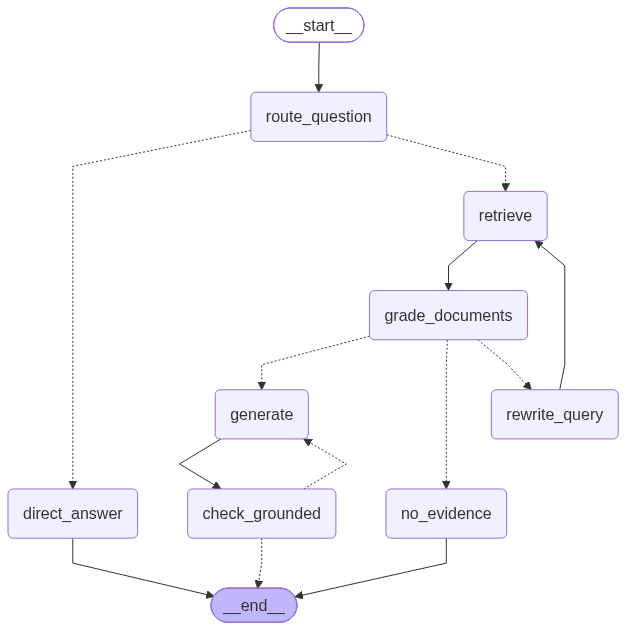

In [ ]:
builder = StateGraph(AgentState)
builder.add_node("route_question", route_question_node)
builder.add_node("direct_answer", direct_answer_node)
builder.add_node("retrieve", corrective_retrieve_node)
builder.add_node("grade_documents", grade_documents_node)
builder.add_node("rewrite_query", rewrite_query_node)
builder.add_node("no_evidence", no_evidence_node)
builder.add_node("generate", agent_generate_node)
builder.add_node("check_grounded", check_grounded_node)

builder.add_edge(START, "route_question")
builder.add_conditional_edges("route_question", decide_route)
builder.add_edge("direct_answer", END)

builder.add_edge("retrieve", "grade_documents")
builder.add_conditional_edges("grade_documents", decide_after_grading)
builder.add_edge("rewrite_query", "retrieve")
builder.add_edge("no_evidence", END)

builder.add_edge("generate", "check_grounded")
builder.add_conditional_edges("check_grounded", decide_after_check)

agent_graph = builder.compile()
show_graph(agent_graph)

### 빠른 동작 확인

본격적인 RAGAS 평가 전에, 1-3에서 만든 그래프가 그대로 동작하는지 한 문항으로 확인한다.

In [ ]:
_ = run(
    agent_graph,
    "생성형 인공지능 결과물에 대해 사업자는 어떤 표시 의무가 있나요?"
)

Q. 생성형 인공지능 결과물에 대해 사업자는 어떤 표시 의무가 있나요?
  [route] law
  [retrieve] query = 생성형 인공지능 결과물에 대해 사업자는 어떤 표시 의무가 있나요?


KeyboardInterrupt: 

## RAGAS 평가 준비
- RAGAS(RAG Assessment)는 RAG(Retrieval-Augmented Generation) 파이프라인의 품질을 LLM-as-judge 방식으로 자동 채점하는 평가 프레임워크/라이브러리
- 대표 지표
  - Faithfulness(충실성): 답변의 각 주장이 실제로 검색된 context에 근거하는가 — 지어낸 내용(환각)이 있는지
  - ResponseRelevancy(답변 관련성): 답변이 질문에 실제로 적합한가
  - Context Precision/Recall(컨텍스트 정밀도): 검색된 문서가 질문에 관련 있는가 / 필요한 정답 근거를 빠짐없이 찾았는가
  - (ground truth가 있으면) Answer Correctness처럼 정답 문장과 직접 비교하는 지표도 있음

`eval/evaluate.py`의 `load_golden_set()`을 그대로 재사용해 25문항을 불러오고,  
각 문항을 `agent_graph`로 실행해 RAGAS가 요구하는 형식(`user_input`, `response`, `retrieved_contexts`)으로 모은다.  

In [ ]:
# uv add ragas "langchain-community<0.4" pillow

In [ ]:
from ragas import EvaluationDataset, evaluate
from ragas.metrics import Faithfulness, LLMContextPrecisionWithoutReference, ResponseRelevancy

from common.ai_model import get_embedding_model
from eval.evaluate import load_golden_set

golden_set = load_golden_set()
print(f"Golden Set: {len(golden_set)}문항")

Golden Set: 25문항


### Agent 실행 결과 수집

`route="general"`로 빠지거나 재작성 루프 끝에 `no_evidence`로 끝난 문항은 `documents`가 비어 있어  
`retrieved_contexts`가 필요한 지표(`Faithfulness`, `LLMContextPrecisionWithoutReference`)를 계산할 수 없다.  
이런 문항은 RAGAS 평가에서 제외하고 id만 따로 모아 "검색 실패율"로 함께 보고한다.  

In [ ]:
def collect_ragas_samples(graph, items: list) -> tuple[list[dict], list[str]]:
    """golden_set 전체에 대해 그래프를 실행해 RAGAS용 샘플을 모은다.

    documents가 빈 문항(general 라우팅ㆍno_evidence)은 context 기반 지표를
    계산할 수 없으므로 제외하고, 그 id만 skipped로 반환한다.
    """
    samples, skipped = [], []
    for item in items:
        state = graph.invoke({"question": item.question})
        contexts = [doc.chunk.text for doc in state.get("documents", [])]
        if not contexts:
            skipped.append(item.id)
            continue
        samples.append(
            {
                "user_input": item.question,
                "response": state["answer"],
                "retrieved_contexts": contexts,
            }
        )
    return samples, skipped

In [6]:
samples, skipped_ids = collect_ragas_samples(agent_graph, golden_set)
print(f"평가 대상: {len(samples)}/{len(golden_set)}문항 (검색 실패로 제외: {skipped_ids})")

NameError: name 'collect_ragas_samples' is not defined

### RAGAS 실행

RAGAS 내부 LLM 호출(statement 추출ㆍverdict 판정)은 `judge_llm`(`max_tokens=256`)보다 긴 출력이 필요해
출력이 잘리면 `Faithfulness`가 `nan`으로 나온다. 그래서 라우팅ㆍ평가용 `judge_llm`과는 별도로
`max_tokens`를 넉넉히 둔 `ragas_llm`을 평가 전용으로 사용한다.

In [ ]:
ragas_llm = get_llm_model(max_tokens=2048)
embedding_model = get_embedding_model()

dataset = EvaluationDataset.from_list(samples)
ragas_metrics = [Faithfulness(), ResponseRelevancy(), LLMContextPrecisionWithoutReference()]

result = evaluate(
    dataset=dataset,
    metrics=ragas_metrics,
    llm=ragas_llm,
    embeddings=embedding_model,
)
result

Evaluating:   0%|          | 0/75 [00:00<?, ?it/s]

{'faithfulness': 0.9577, 'answer_relevancy': 0.5259, 'llm_context_precision_without_reference': 0.9833}

In [ ]:
df = result.to_pandas()
print(f"검색 실패율(제외): {len(skipped_ids)}/{len(golden_set)}")
df[["user_input", "faithfulness", "answer_relevancy", "llm_context_precision_without_reference"]]

검색 실패율(제외): 0/25


,user_input,faithfulness,answer_relevancy,llm_context_precision_without_reference
0,인공지능기본법의 목적은 무엇인가요?,1.000000,0.638566,1.000000
1,이 법에서 인공지능은 어떻게 정의되나요?,0.800000,0.646698,1.000000
2,고영향 인공지능이란 무엇인가요?,1.000000,0.441816,1.000000
3,생성형 인공지능이란 무엇인가요?,1.000000,0.445285,1.000000
4,이 법은 국외에서 이루어진 행위에도 적용되나요?,0.666667,0.560529,1.000000
5,인공지능 기본계획은 몇 년마다 수립해야 하나요?,1.000000,0.651399,1.000000
6,국가인공지능전략위원회의 위원장은 누구인가요?,1.000000,0.543142,1.000000
7,국가인공지능전략위원회가 심의·의결하는 사항에는 어떤 것이 있나요?,1.000000,0.473932,1.000000
8,인공지능정책센터는 어떤 업무를 수행하나요?,1.000000,0.564955,0.750000
9,인공지능안전연구소는 누가 운영할 수 있나요?,1.000000,0.643281,1.000000


In [ ]:
df.sort_values("faithfulness").head(3)        # faithfulness 낮은 문항부터

,user_input,retrieved_contexts,response,faithfulness,answer_relevancy,llm_context_precision_without_reference
24,국내대리인을 지정하지 않으면 어떤 제재를 받나요?,[제43조(과태료)\n① 다음 각 호의 어느 하나에 해당하는 자에게는 3천만원 이하...,국내대리인을 지정하지 않으면 3천만원 이하의 과태료를 부과받습니다. 이는 제36조제...,0.600000,0.000000,1.0
4,이 법은 국외에서 이루어진 행위에도 적용되나요?,[제4조(적용범위)\n① 이 법은 국외에서 이루어진 행위라도 국내 시장 또는 이용자...,"네, 이 법은 국외에서 이루어진 행위라도 국내 시장 또는 이용자에게 영향을 미치는 ...",0.666667,0.560529,1.0
1,이 법에서 인공지능은 어떻게 정의되나요?,[제2조(정의)\n이 법에서 사용하는 용어의 뜻은 다음과 같다.\n<개정 2026....,"이 법에서 인공지능은 ""인공지능시스템""으로 정의되며, 이는 다양한 수준의 자율성과 ...",0.800000,0.646698,1.0


In [ ]:
df.sort_values("answer_relevancy").head(3)    # relevancy 낮은 문항부터

,user_input,retrieved_contexts,response,faithfulness,answer_relevancy,llm_context_precision_without_reference
24,국내대리인을 지정하지 않으면 어떤 제재를 받나요?,[제43조(과태료)\n① 다음 각 호의 어느 하나에 해당하는 자에게는 3천만원 이하...,국내대리인을 지정하지 않으면 3천만원 이하의 과태료를 부과받습니다. 이는 제36조제...,0.6,0.000000,1.0
16,인공지능사업자가 고영향 인공지능을 제공할 때 검·인증을 받아야 하나요?,[제33조(고영향 인공지능의 확인)\n① 인공지능사업자는 인공지능 또는 이를 이용한...,"인공지능사업자가 고영향 인공지능을 제공하는 경우, 사전에 검·인증을 받도록 노력하여...",1.0,0.414062,1.0
17,생성형 인공지능으로 만든 결과물은 어떻게 표시해야 하나요?,[제31조(인공지능 투명성 확보 의무)\n① 인공지능사업자는 고영향 인공지능이나 생...,생성형 인공지능으로 만든 결과물은 그 결과물이 생성형 인공지능에 의해 생성되었다는 ...,1.0,0.426494,1.0


---
## 정리

| 핵심 개념 | 역할 |
|---|---|
| `EvaluationDataset.from_list` | `{user_input, response, retrieved_contexts}` 딱셔너리 리스트를 RAGAS 입력 형식으로 변환 |
| `Faithfulness` / `ResponseRelevancy` / `LLMContextPrecisionWithoutReference` | ground truth 없이 계산 가능한 LLM-as-judge 지표 |
| `evaluate(llm=..., embeddings=...)` | 지표 계산에 쓸 LLM/임베딩을 명시적으로 주입 |

- `eval/evaluate.py`(규칙 기반, 결정적ㆍ저비용)와 이번 RAGAS 평가(LLM-as-judge, 세밀하지만 비용ㆍ지연 발생)는 서로 대체재가 아니라 **보완 관계**다.
- route/no_evidence로 빠져 `documents`가 빈 문항은 RAGAS 지표 자체가 정의되지 않으므로, 검색 실패율을 별도 지표로 같이 봐야 전체 품질을 왜곡 없이 파악할 수 있다.
